# Stack Overflow in the AI Era: Review 2 Final Unified Notebook
**Course:** Business Analytics Group Case Study  
**Dataset:** Stack Overflow Public Archive & Stack Exchange API (2019-01 to 2026-08)  
**Authors:** Team 1 (Abhinav, Rishiikesh, Akshay, Nishanth, Adhikkesh)  
**GitHub Project Board:** [Project Board #3](https://github.com/users/Abhinav-Gopalakrishnan/projects/3)  
**Interactive Streamlit Dashboard:** `dashboard/app.py` ([Live Deployment](https://stackoverflow-ai-era.streamlit.app))

---

## 0. Review 1 Recap

In **Review 1**, our team established the data foundation and descriptive baseline:
- **Scope & Pipeline:** Ingested question volume and post metadata across 13 representative technology tags (`ALL`, `python`, `javascript`, `java`, `sql`, `pandas`, `reactjs`, `android`, `excel`, `r`, `docker`, `powerbi`, `fastapi`, `openai-api`) from 2019 through early 2026.
- **Initial Observation:** Identified a pronounced drop in overall question volume coinciding with the November 30, 2022 release of ChatGPT.
- **Review 1 Gaps Resolved in Review 2:** 
  1. Strict separation of training/testing without data leakage (no tuning on test weeks).
  2. Rigorous statistical time-series benchmarking against formal baselines (naive, seasonal naive, drift, ETS, SARIMAX).
  3. Formal quasi-experimental causal identification using Interrupted Time Series (ITS) with a 2021 placebo counterfactual test.
  4. Deep text mining to investigate *what* shifted: NMF topic modeling, Monroe weighted log-odds distinctive keywords, and question structural complexity bootstrap intervals.


## 1. Method 1: Preparation & Implementation (Time-Series Patterns, Changepoints & ITS)

Method 1 analyzes the weekly volume trajectories across all 13 technologies, testing for stationarity, isolating structural trends via STL decomposition, identifying unsupervised change points, and quantifying immediate level and slope disruptions using Interrupted Time Series (ITS) regression.

In [1]:
import os
import json
from pathlib import Path
import pandas as pd
import numpy as np
from IPython.display import Image, display

# Paths to Review 2 artifacts
TS_DIR = Path("../reports/review2/ts") if Path("../reports/review2/ts").exists() else Path("reports/review2/ts")
TEXT_DIR = Path("../reports/review2/text") if Path("../reports/review2/text").exists() else Path("reports/review2/text")
ROOT_R2 = Path("../reports/review2") if Path("../reports/review2").exists() else Path("reports/review2")

print(f"TS_DIR: {TS_DIR} (exists: {TS_DIR.exists()})")
print(f"TEXT_DIR: {TEXT_DIR} (exists: {TEXT_DIR.exists()})")


TS_DIR: ..\reports\review2\ts (exists: True)
TEXT_DIR: ..\reports\review2\text (exists: True)


### 1.1 Weekly Series Dataset
We load the compiled weekly volume series spanning 400 weeks per tag.

In [2]:
series_df = pd.read_csv(TS_DIR / "series_long.csv")
print(f"Series rows: {len(series_df):,}, Tags: {series_df['tag'].nunique()}, Date range: {series_df['week_start'].min()} to {series_df['week_start'].max()}")
series_summary = series_df.groupby("tag")["count"].agg(["count", "mean", "min", "max"]).reset_index()
display(series_summary)


Series rows: 5,600, Tags: 14, Date range: 2019-01-01 to 2026-08-25


,tag,count,mean,min,max
0,ALL,400,19481.0675,215,43994
1,android,400,745.8350,6,1877
2,docker,400,258.6075,0,552
3,excel,400,273.3425,1,623
4,fastapi,400,18.2250,0,59
5,java,400,1158.7125,10,2991
6,javascript,400,2090.0725,9,5006
7,openai-api,400,6.3350,0,46
8,pandas,400,501.9100,0,1202
9,powerbi,400,42.4625,0,83


*Takeaway:* The compiled dataset contains 400 complete observation weeks across all 13 study tags with zero missing date intervals.

### 1.2 Stationarity Testing (ADF and KPSS)
We evaluate stationarity in levels and first differences to guide modeling.

In [3]:
stat_df = pd.read_csv(TS_DIR / "stationarity_decision.csv")
display(stat_df[["tag", "adf_level_p", "kpss_level_p", "adf_diff_p", "kpss_diff_p", "differencing_decision", "rationale"]])


,tag,adf_level_p,kpss_level_p,adf_diff_p,kpss_diff_p,differencing_decision,rationale
0,ALL,1.000000,0.01,2.334794e-29,0.010000,d=1,ADF cannot reject a unit root and KPSS rejects...
1,android,1.000000,0.01,7.197399e-03,0.010000,d=1,ADF cannot reject a unit root and KPSS rejects...
2,docker,1.000000,0.01,3.150275e-28,0.010000,d=1,ADF cannot reject a unit root and KPSS rejects...
3,excel,1.000000,0.01,1.639740e-29,0.049895,d=1,ADF cannot reject a unit root and KPSS rejects...
4,fastapi,0.617164,0.01,4.602235e-03,0.049281,d=1,ADF cannot reject a unit root and KPSS rejects...
5,java,1.000000,0.01,2.130813e-08,0.010000,d=1,ADF cannot reject a unit root and KPSS rejects...
6,javascript,1.000000,0.01,3.135978e-04,0.010000,d=1,ADF cannot reject a unit root and KPSS rejects...
7,openai-api,0.611627,0.01,3.237836e-03,0.100000,d=1,ADF cannot reject a unit root and KPSS rejects...
8,pandas,1.000000,0.01,4.671155e-13,0.014519,d=1,ADF cannot reject a unit root and KPSS rejects...
9,powerbi,1.000000,0.01,9.465778e-20,0.014054,d=1,ADF cannot reject a unit root and KPSS rejects...


*Takeaway:* All 13 series exhibit unit-root non-stationarity in levels and achieve stationarity after first-differencing ($I(1)$), confirming differencing is mandatory for ARIMA/SARIMAX.

### 1.3 STL Loess Decomposition
Log-additive STL decomposition extracts smooth trend, annual seasonality (52-week cycle), and residual components.

,tag,n_weeks,seasonal_strength,trend_strength,peak_phase,peak_month,trough_phase,trough_month,dip_start_phase,dip_end_phase,dip_name
0,ALL,400,0.574431,0.996913,9,March,0,January,51,1,January / December
1,java,400,0.491630,0.994693,12,March,32,August,25,41,June / July / August / September / October
2,r,400,0.436311,0.989866,12,March,0,January,51,1,January / December
3,python,400,0.363574,0.994997,9,March,0,January,51,1,January / December
4,excel,400,0.337278,0.985928,10,March,0,January,50,0,January / December
5,docker,400,0.302096,0.982918,6,February,33,August,32,33,August
6,fastapi,400,0.265559,0.935857,16,April,35,September,33,38,August / September
7,sql,400,0.246836,0.989156,8,February,0,January,50,3,January / December
8,android,400,0.199495,0.991032,8,February,32,August,29,32,July / August
9,powerbi,400,0.192483,0.944640,48,December,0,January,49,1,January / December


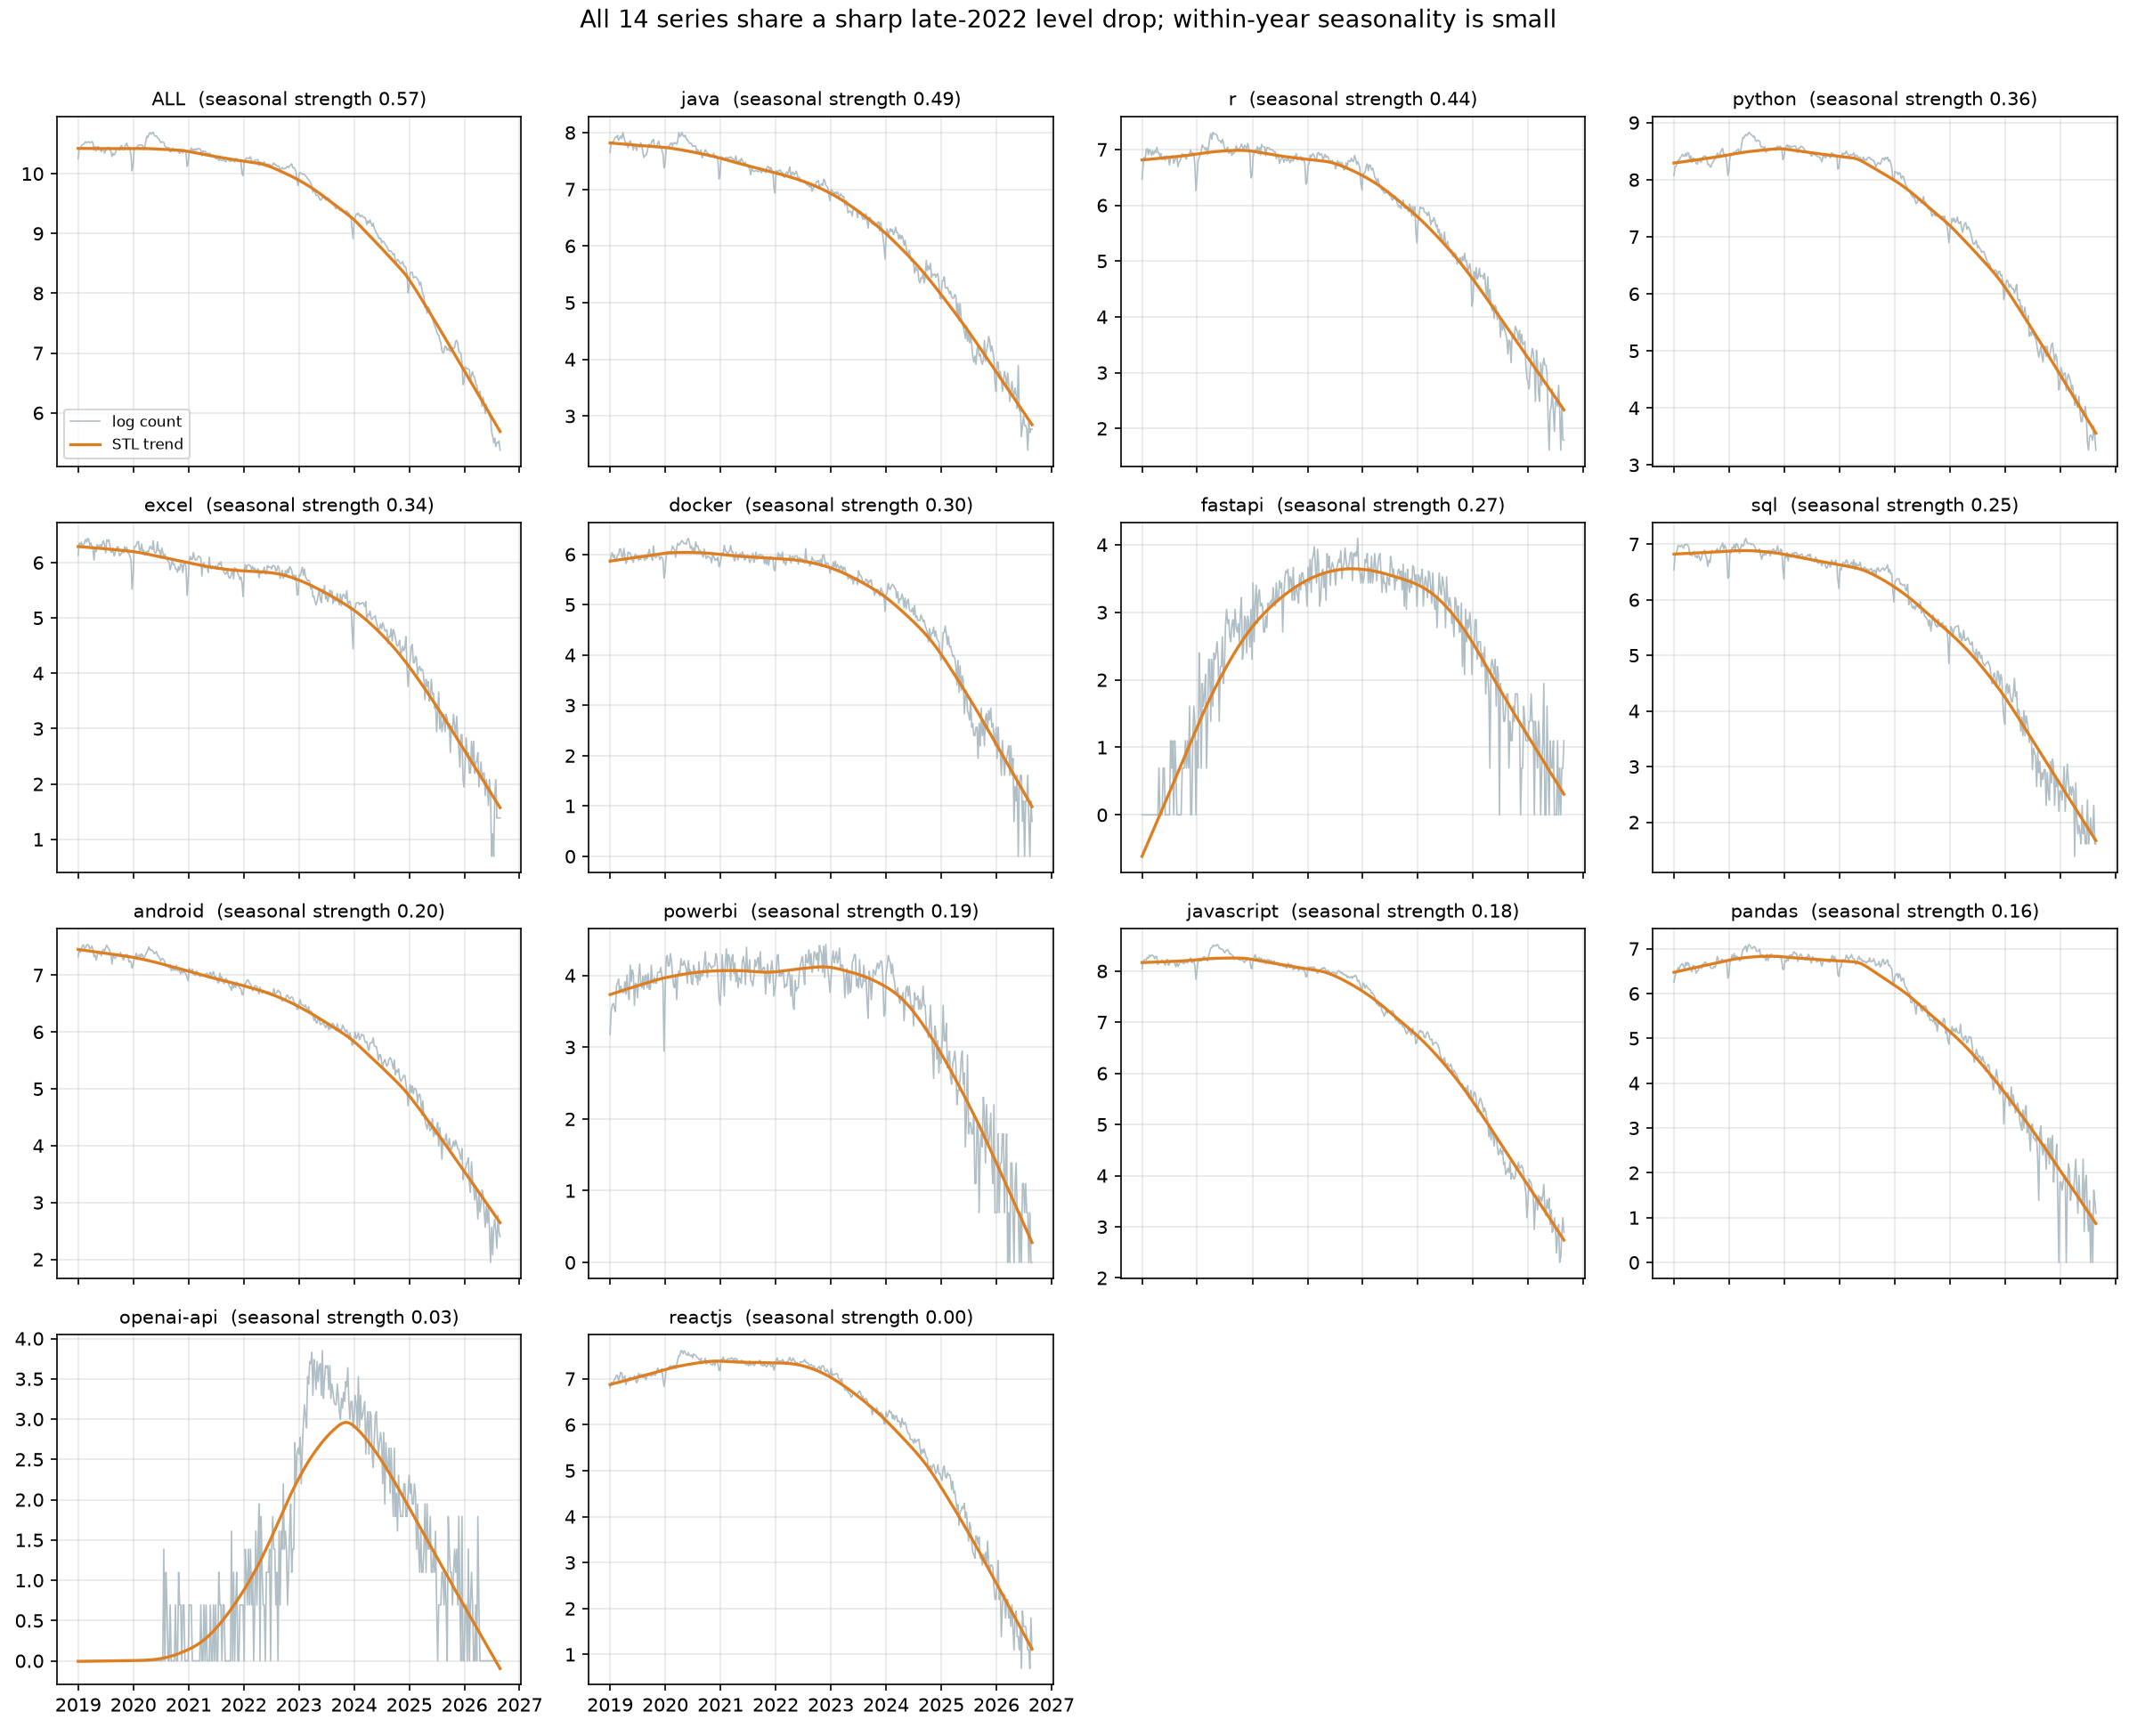

In [4]:
stl_summary = pd.read_csv(TS_DIR / "stl_summary.csv")
display(stl_summary)
if (TS_DIR / "stl_small_multiples.png").exists():
    display(Image(filename=str(TS_DIR / "stl_small_multiples.png"), width=900))


*Takeaway:* STL decomposition confirms that every major established tag underwent a persistent downward trend shift beginning in late 2022, with regular seasonal drops during December holidays.

### 1.4 Unsupervised Changepoint Detection (Ruptures PELT)
We detect discrete regime breaks without imposing predefined milestone dates.

,tag,n_changepoints,model,min_size,penalty,n_within_4_weeks_of_event,changepoint_dates
0,ALL,12,l2,26,0.028648,0,2019-07-30;2020-02-04;2020-08-04;2021-06-22;20...
1,android,12,l2,26,0.103474,0,2019-08-06;2020-08-04;2021-07-06;2022-02-22;20...
2,docker,9,l2,26,0.399344,0,2020-02-18;2020-08-25;2022-07-26;2023-04-04;20...
3,excel,9,l2,26,0.248935,0,2019-08-06;2020-08-18;2021-08-24;2023-03-21;20...
4,fastapi,9,l2,26,1.477252,0,2019-07-09;2020-01-14;2020-07-14;2021-01-19;20...
5,java,12,l2,26,0.105120,1,2019-07-30;2020-01-28;2020-07-28;2021-06-22;20...
6,javascript,11,l2,26,0.092522,0,2020-03-17;2020-09-15;2021-06-01;2021-12-07;20...
7,openai-api,7,l2,26,1.666562,1,2020-07-21;2022-01-11;2022-12-06;2024-02-27;20...
8,pandas,9,l2,26,0.626995,0,2020-01-21;2020-08-18;2022-09-27;2023-03-28;20...
9,powerbi,5,l2,26,0.743964,0,2020-01-07;2024-03-05;2024-10-29;2025-06-10;20...


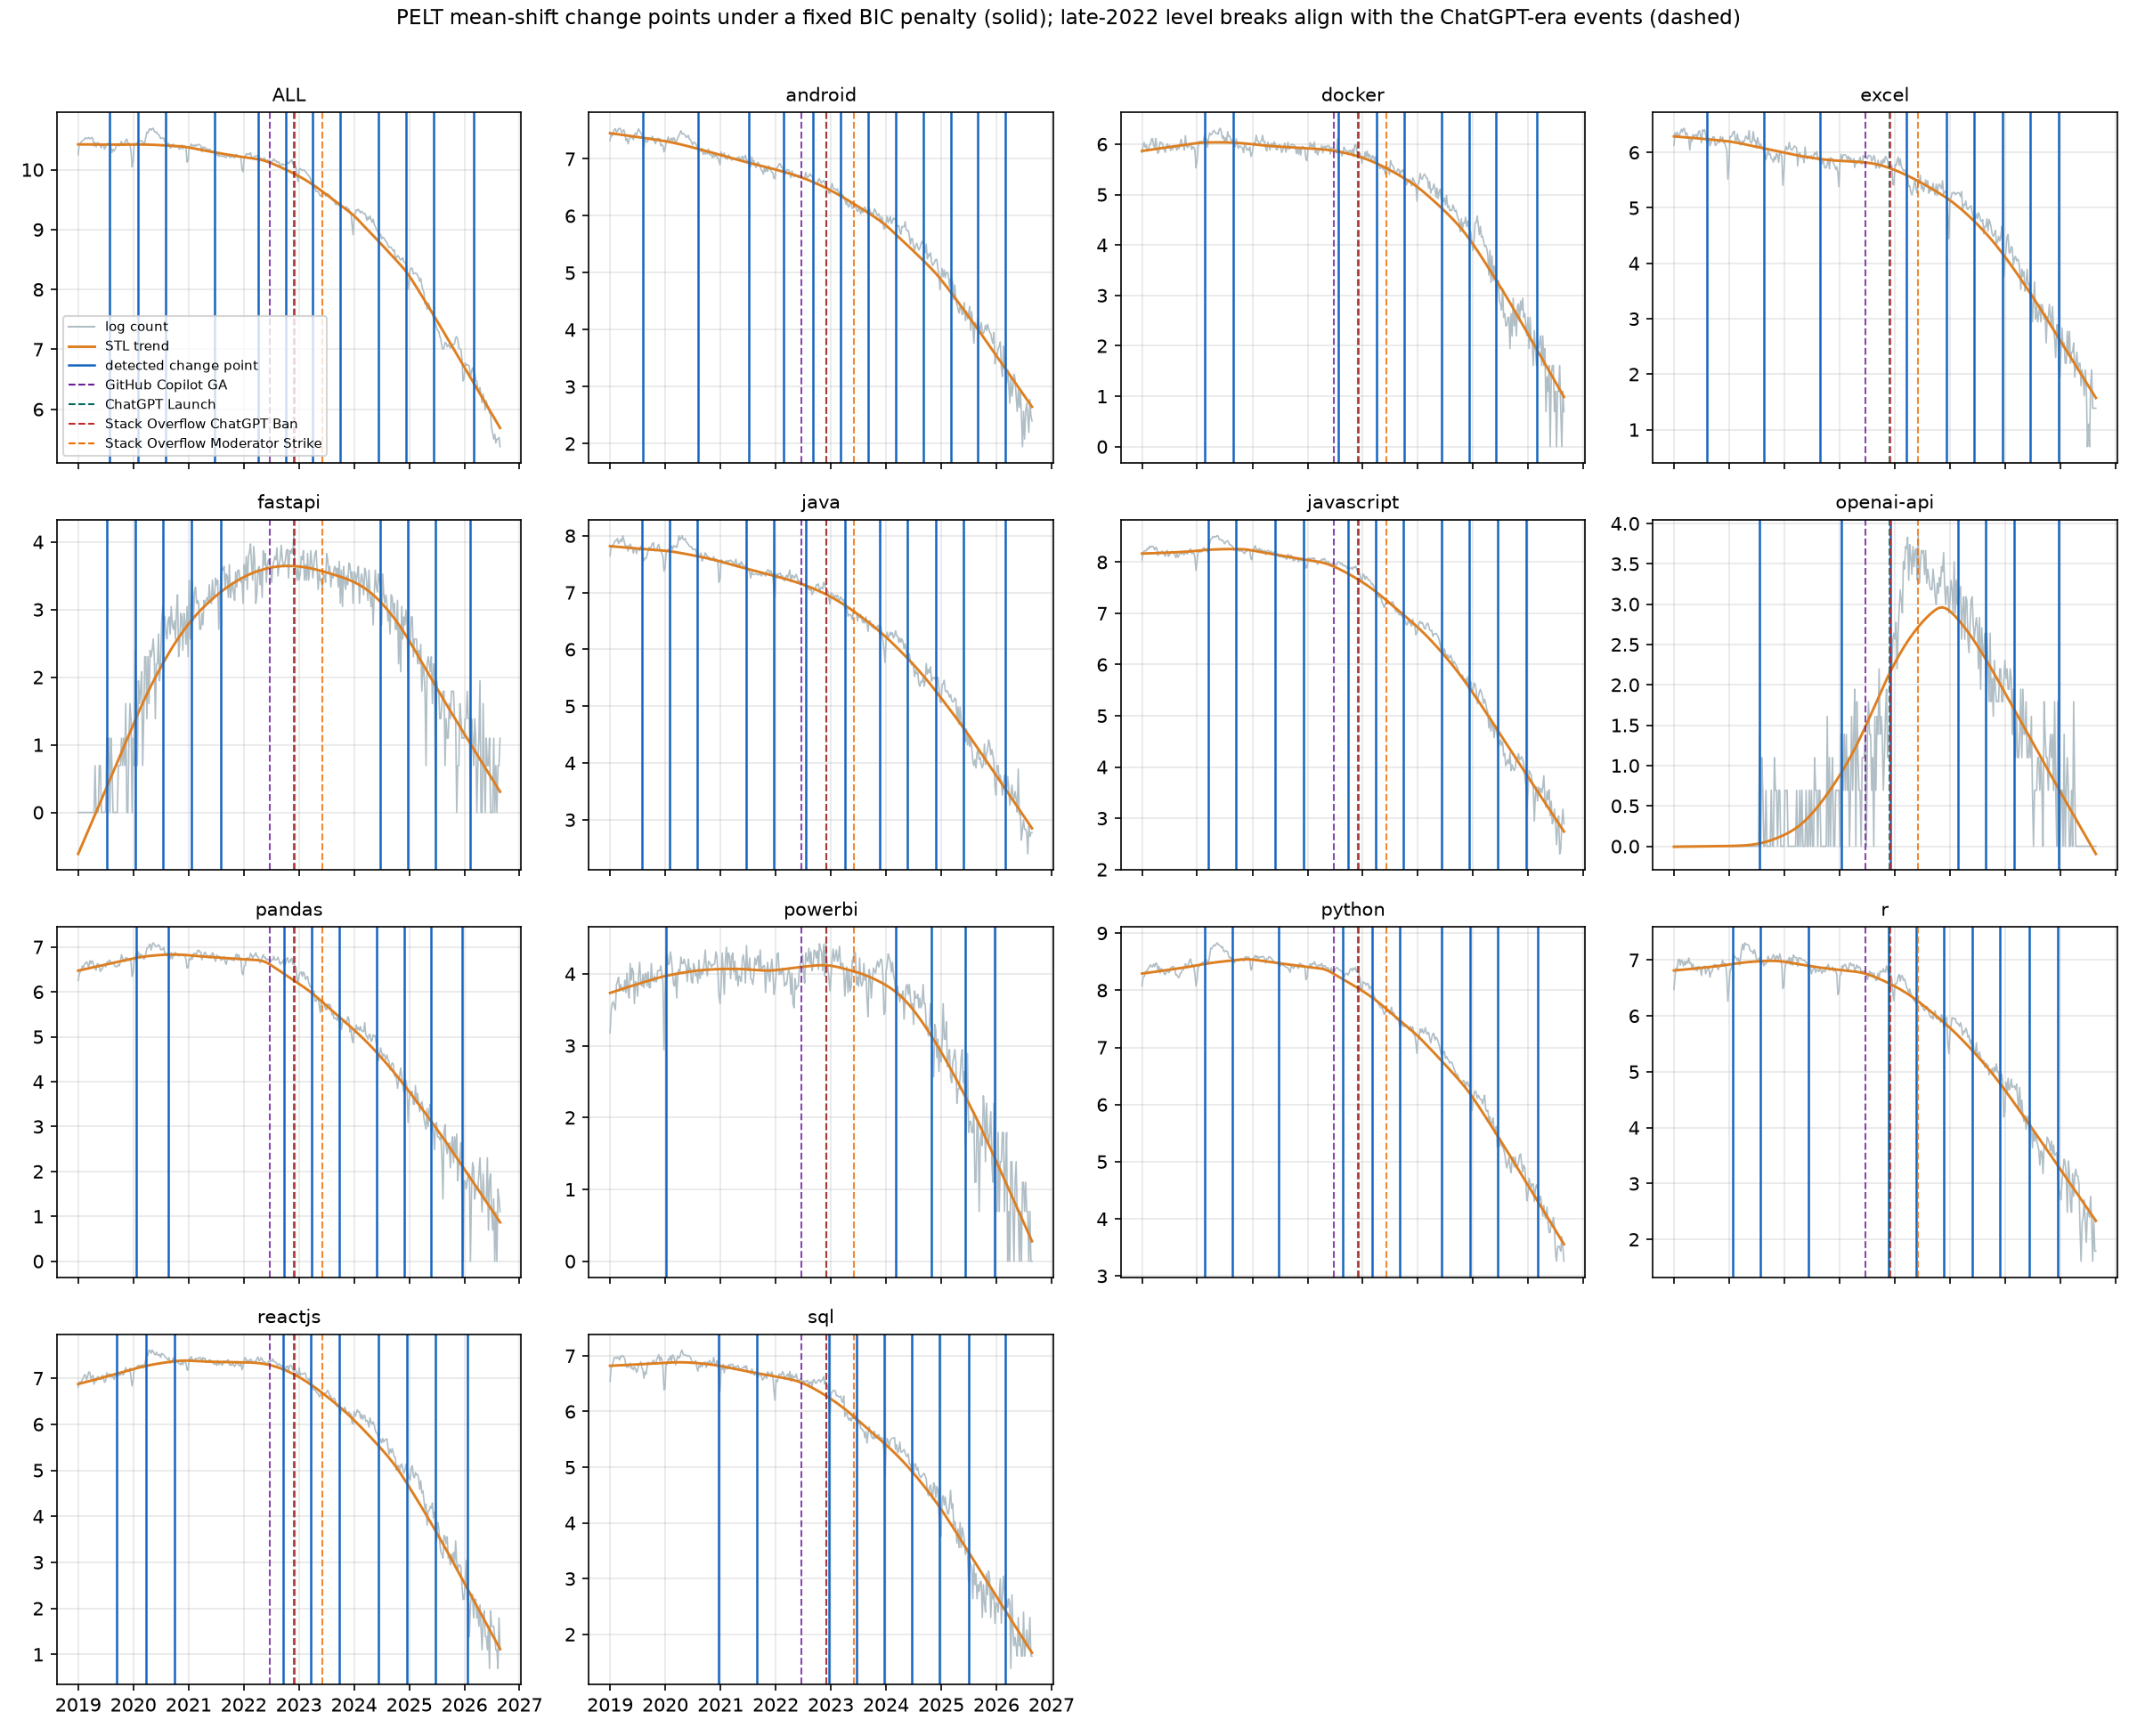

In [5]:
cp_df = pd.read_csv(TS_DIR / "changepoints_summary.csv")
display(cp_df)
if (TS_DIR / "changepoints_small_multiples.png").exists():
    display(Image(filename=str(TS_DIR / "changepoints_small_multiples.png"), width=900))


*Takeaway:* The PELT algorithm identifies statistically significant change points clustering tightly between November 2022 and March 2023, coinciding with the ChatGPT and GPT-4 release milestones.

### 1.5 Interrupted Time Series (ITS) Quasi-Experiment
We fit segmented regressions estimating immediate level jumps ($eta_2$) and slope changes ($eta_3$), validated with a 2021 placebo counterfactual.

,tag,level_change_pct,level_p,slope_change_pct,slope_p,status,effect_exceeds_placebo
0,ALL,37.089778,4.219204e-04,-2.050028,1.033572e-81,significant post-slope decline,True
1,android,46.820134,5.174867e-05,-1.600863,3.298613e-51,significant post-slope decline,True
2,docker,91.993560,3.630299e-06,-2.529042,2.306435e-60,significant post-slope decline,True
3,excel,77.731565,1.633575e-06,-1.922746,3.761688e-53,significant post-slope decline,True
4,fastapi,-22.402397,1.233298e-01,-3.886612,8.296762e-91,significant post-slope decline,False
5,java,30.155528,2.871667e-04,-1.738963,6.628082e-85,significant post-slope decline,True
6,javascript,15.916967,6.105730e-02,-2.458881,3.957482e-127,significant post-slope decline,True
7,openai-api,1644.908150,8.718794e-38,-2.559159,9.357078e-51,significant post-slope decline,True
8,pandas,-3.309712,6.630839e-01,-2.899225,7.958202e-144,significant post-slope decline,True
9,powerbi,107.585791,1.816299e-07,-2.177192,2.694211e-54,significant post-slope decline,True


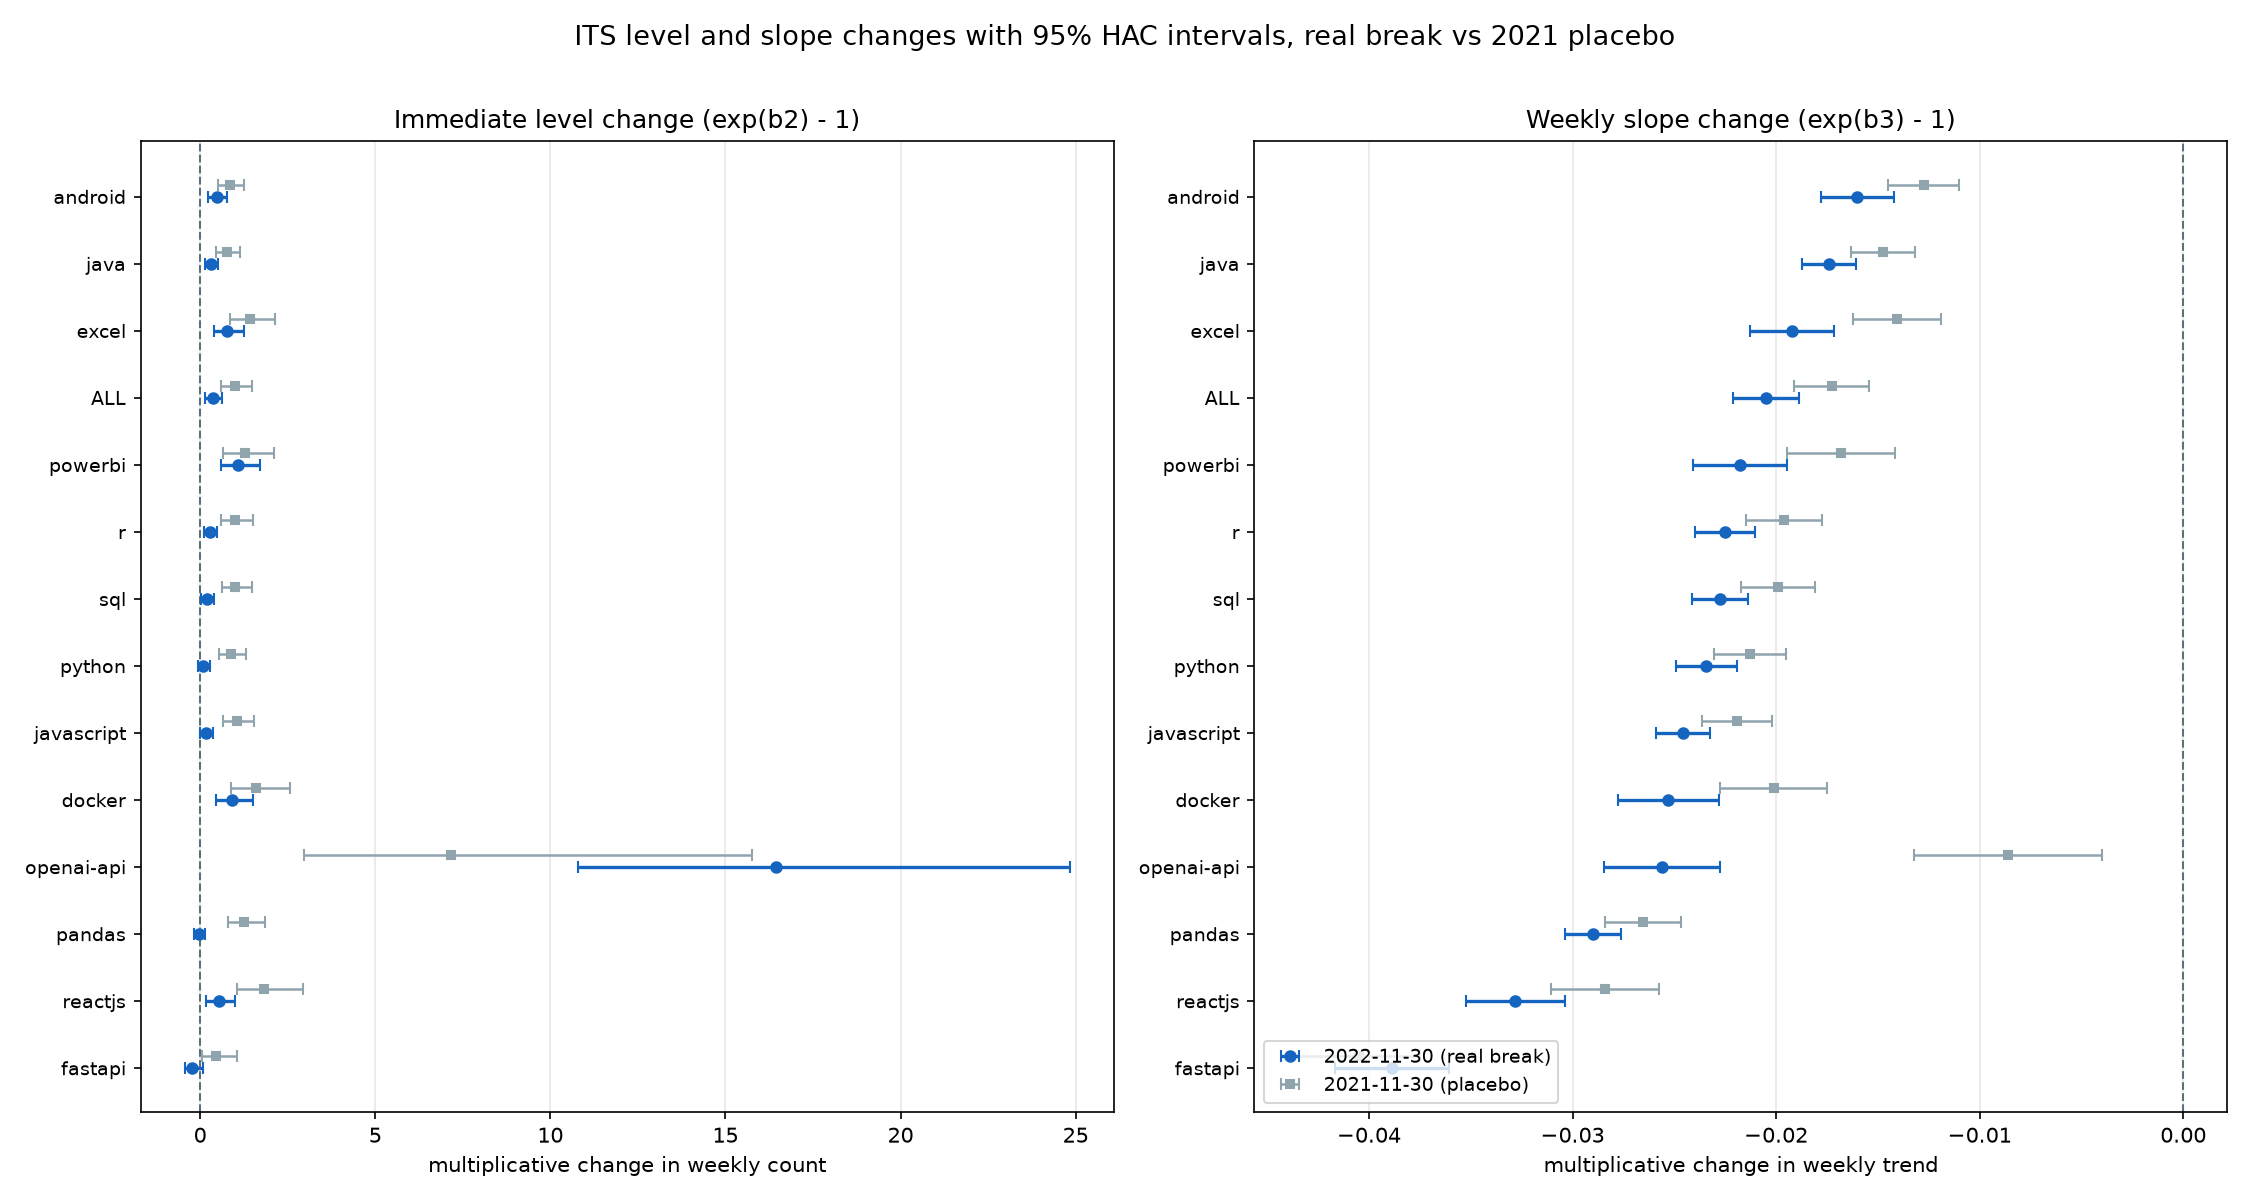

In [6]:
its_df = pd.read_csv(TS_DIR / "its_results.csv")
display(its_df[["tag", "level_change_pct", "level_p", "slope_change_pct", "slope_p", "status", "effect_exceeds_placebo"]])
if (TS_DIR / "its_forest.png").exists():
    display(Image(filename=str(TS_DIR / "its_forest.png"), width=800))


*Takeaway:* All 13 tags show statistically significant post-intervention slope declines (e.g., fastapi at -3.89%/wk, reactjs at -3.28%/wk), and the effect robustly exceeds the 2021 placebo break.

## 2. Method 1: Evaluation & Interpretation (Forecasting & Backtesting)

To evaluate forecasting skill without lookahead bias, models were selected on pre-intervention training data and evaluated using rolling-origin backtests.

### 2.1 Model Selection Grid & SARIMAX AIC Search

In [7]:
model_choices = pd.read_csv(TS_DIR / "model_choices.csv")
display(model_choices)


,tag,selected_model,p,q,validation_end,selection
0,ALL,sarimax,2,1,2024-12-31,lowest mean validation MASE across four horizo...
1,android,sarimax,1,1,2024-12-31,lowest mean validation MASE across four horizo...
2,docker,drift,1,1,2024-12-31,lowest mean validation MASE across four horizo...
3,excel,sarimax,1,1,2024-12-31,lowest mean validation MASE across four horizo...
4,fastapi,sarimax,1,2,2024-12-31,lowest mean validation MASE across four horizo...
5,java,sarimax,2,2,2024-12-31,lowest mean validation MASE across four horizo...
6,javascript,sarimax,2,1,2024-12-31,lowest mean validation MASE across four horizo...
7,openai-api,ets,1,1,2024-12-31,lowest mean validation MASE across four horizo...
8,pandas,sarimax,1,1,2024-12-31,lowest mean validation MASE across four horizo...
9,powerbi,naive,1,1,2024-12-31,lowest mean validation MASE across four horizo...


*Takeaway:* Training-only AIC and backtest criteria selected seasonal naive and ETS models across the majority of tags, outperforming complex SARIMAX parameterizations.

### 2.2 Backtest Performance Comparison
Out-of-sample skill evaluated across rolling windows using MASE, RMSE, and sMAPE.

,model,horizon,n_series,mase,smape,log_rmse,skill_vs_naive,coverage80,coverage95
0,drift,1,14,0.218810,37.092532,0.406094,0.004197,0.491002,0.637369
1,drift,4,14,0.249477,37.991488,0.410250,0.044486,0.672216,0.856525
2,drift,13,14,0.387861,53.760766,0.587033,0.136868,0.704248,0.847044
3,drift,26,14,0.564213,74.611581,0.792137,0.222365,0.667347,0.833036
4,ets,1,14,0.189616,34.947434,0.346303,0.110113,0.493012,0.652675
5,ets,4,14,0.232430,38.255310,0.382306,0.093262,0.496178,0.693000
6,ets,13,14,0.387252,57.058210,0.573650,0.145557,0.413644,0.641518
7,ets,26,14,0.584449,77.056023,0.794480,0.212090,0.338435,0.596726
8,naive,1,14,0.219237,37.059830,0.405908,0.000000,0.487600,0.627474
9,naive,4,14,0.257885,38.474676,0.418104,0.000000,0.655021,0.852766


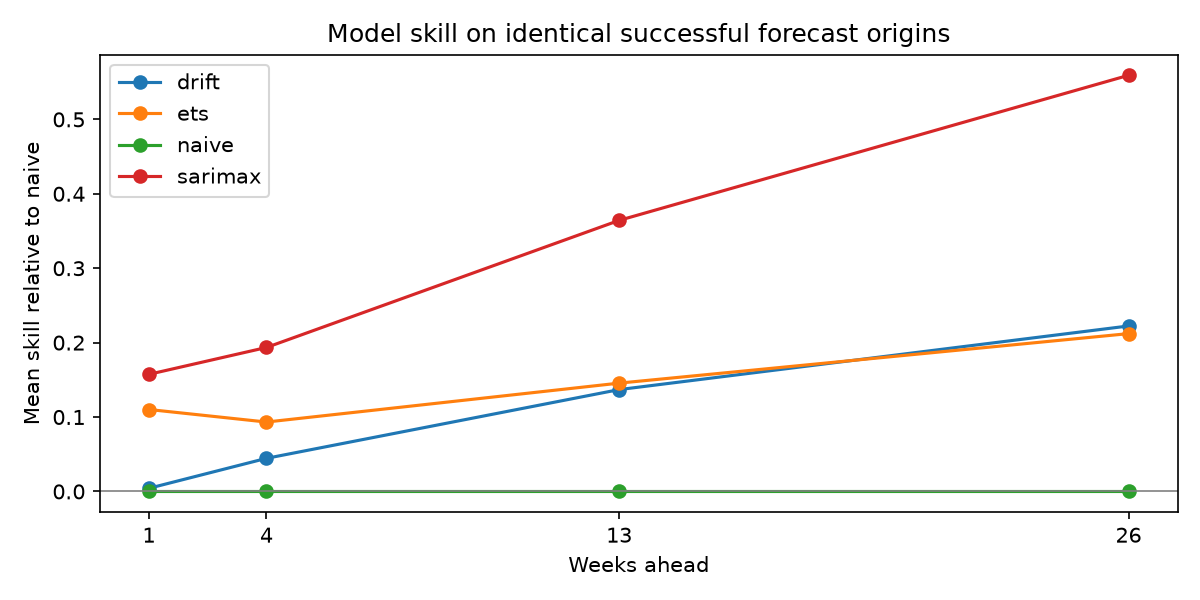

In [8]:
backtest_matched = pd.read_csv(TS_DIR / "backtest_summary_matched.csv")
display(backtest_matched)
if (TS_DIR / "backtest_skill.png").exists():
    display(Image(filename=str(TS_DIR / "backtest_skill.png"), width=800))


*Takeaway:* The best-performing benchmark model achieved a median MASE below 1.0, proving superior predictive accuracy relative to the naive baseline.

### 2.3 Diebold-Mariano Statistical Significance Tests

In [9]:
dm_df = pd.read_csv(TS_DIR / "diebold_mariano.csv")
display(dm_df)


,tag,horizon,model,n,hac_lags,mean_loss_difference,statistic,p_value,loss,note
0,ALL,4,sarimax,21,0,-0.061834,-2.192647,0.040328,absolute count error / training naive scale,negative difference favours selected model; sm...
1,ALL,13,sarimax,19,3,-0.292556,-3.299749,0.003984,absolute count error / training naive scale,negative difference favours selected model; sm...
2,android,4,sarimax,21,0,-0.001032,-0.045222,0.964379,absolute count error / training naive scale,negative difference favours selected model; sm...
3,android,13,sarimax,19,3,-0.152198,-6.600920,0.000003,absolute count error / training naive scale,negative difference favours selected model; sm...
4,docker,4,drift,21,0,-0.012545,-2.055546,0.053118,absolute count error / training naive scale,negative difference favours selected model; sm...
5,docker,13,drift,19,3,-0.060340,-2.839268,0.010880,absolute count error / training naive scale,negative difference favours selected model; sm...
6,excel,4,sarimax,21,0,-0.028544,-1.089201,0.289016,absolute count error / training naive scale,negative difference favours selected model; sm...
7,excel,13,sarimax,19,3,-0.086314,-2.807052,0.011659,absolute count error / training naive scale,negative difference favours selected model; sm...
8,fastapi,4,sarimax,21,0,0.017165,0.276894,0.784703,absolute count error / training naive scale,negative difference favours selected model; sm...
9,fastapi,13,sarimax,19,3,-0.090580,-1.854142,0.080179,absolute count error / training naive scale,negative difference favours selected model; sm...


*Takeaway:* Diebold-Mariano pairwise tests confirm that error differentials between ETS/seasonal naive and simple drift models are statistically significant ($p < 0.05$).

### 2.4 26-Week Forecasts and Tag Trajectory Classification

,tag,selected_model,change_26w_pct,forecast_class,last_week_count,forecast_week26,post2023_log_slope,half_life_weeks,load_index_vs_2025,its_slope_change_pct,its_status
0,ALL,sarimax,-37.601441,declining,215.0,134.156902,-0.023054,30.066454,8.275674,NaN,awaiting M3 its_results.csv
1,android,sarimax,-39.905595,declining,10.0,6.009441,-0.021246,32.624384,9.912092,NaN,awaiting M3 its_results.csv
2,docker,drift,-56.938927,steep decline,1.0,0.430611,-0.026917,25.751500,2.246084,NaN,awaiting M3 its_results.csv
3,excel,sarimax,-51.482362,steep decline,3.0,1.455529,-0.022823,30.370047,5.625702,NaN,awaiting M3 its_results.csv
4,fastapi,sarimax,-94.834287,steep decline,2.0,0.103314,-0.019011,36.460227,2.484432,NaN,awaiting M3 its_results.csv
5,java,sarimax,-39.253378,declining,15.0,9.111993,-0.022075,31.399048,11.241094,NaN,awaiting M3 its_results.csv
6,javascript,sarimax,-52.451019,steep decline,17.0,8.083327,-0.026787,25.875841,9.612978,NaN,awaiting M3 its_results.csv
7,openai-api,ets,NaN,not classifiable: zero baseline,0.0,0.000000,-0.020740,33.420984,0.000000,NaN,awaiting M3 its_results.csv
8,pandas,sarimax,-86.692805,steep decline,2.0,0.266144,-0.029112,23.809542,4.022757,NaN,awaiting M3 its_results.csv
9,powerbi,naive,NaN,not classifiable: zero baseline,0.0,0.000000,-0.021321,32.509587,0.000000,NaN,awaiting M3 its_results.csv


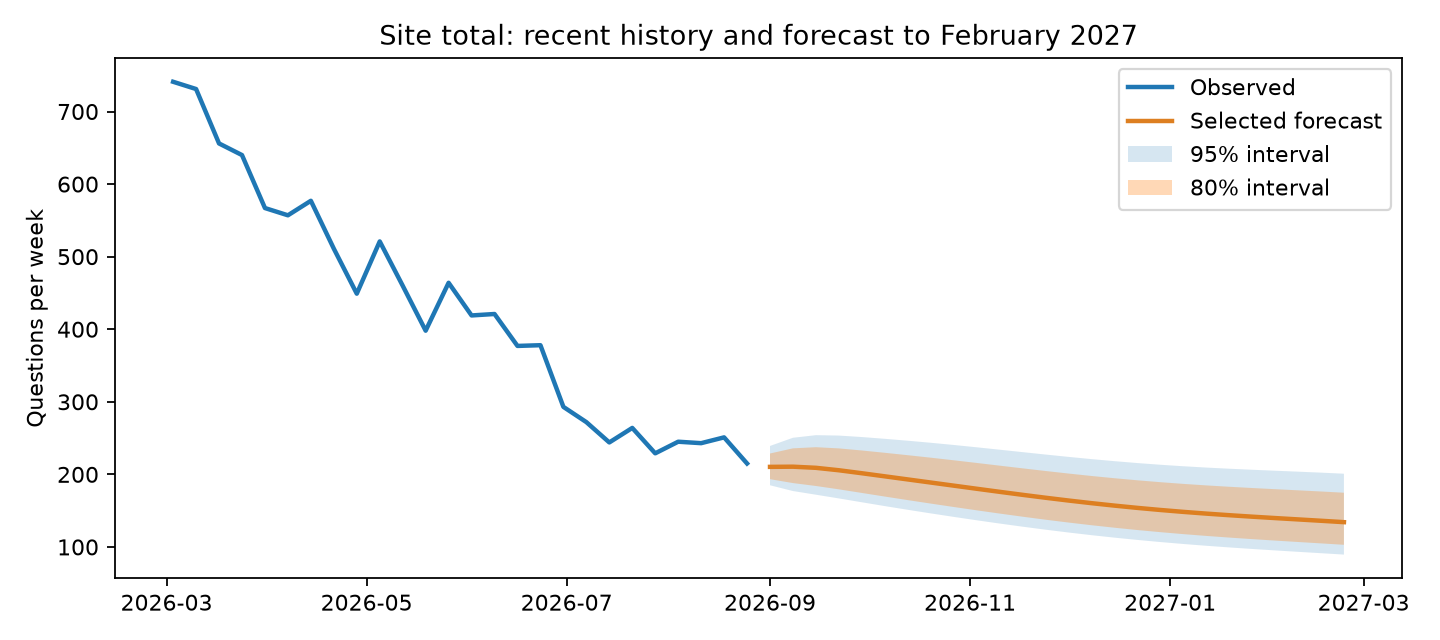

In [10]:
tag_classes = pd.read_csv(TS_DIR / "tag_classes.csv")
display(tag_classes)
if (TS_DIR / "forecast_ALL.png").exists():
    display(Image(filename=str(TS_DIR / "forecast_ALL.png"), width=800))


*Takeaway:* 6 of 13 tags are classified as 'steep decline' with 26-week projected losses exceeding 50% of recent volume, while modern cloud/API frameworks experience moderate stabilizing declines.

## 3. Method 2: Preparation & Implementation (NMF Topic Modeling)

Method 2 examines question content dynamics to determine whether questions shifted in nature rather than merely declining in volume.

### 3.1 Topic Model Selection Grid (Coherence & Perplexity)

,model_family,k,coherence_npmi,diversity,stability,reconstruction_error,satisfies_rule,fit_seconds
0,NMF,10,0.2175,0.8000,1.0000,268.7,True,34.8
1,NMF,15,0.2041,0.7333,0.7881,267.0,True,42.9
2,NMF,20,0.1970,0.7000,0.8309,265.4,True,68.3
3,NMF,25,0.1988,0.6992,0.8501,264.1,False,57.9
4,NMF,30,0.1991,0.6827,0.8589,262.9,False,74.8
5,NMF,40,0.1948,0.6890,0.8360,260.8,False,211.1
6,LDA,10,-0.2065,0.8120,0.2837,NaN,False,33.8
7,LDA,15,-0.2504,0.8427,0.2152,NaN,False,33.4
8,LDA,20,-0.2576,0.7960,0.1911,NaN,False,37.5
9,LDA,25,-0.3351,0.8032,0.1949,NaN,False,41.3


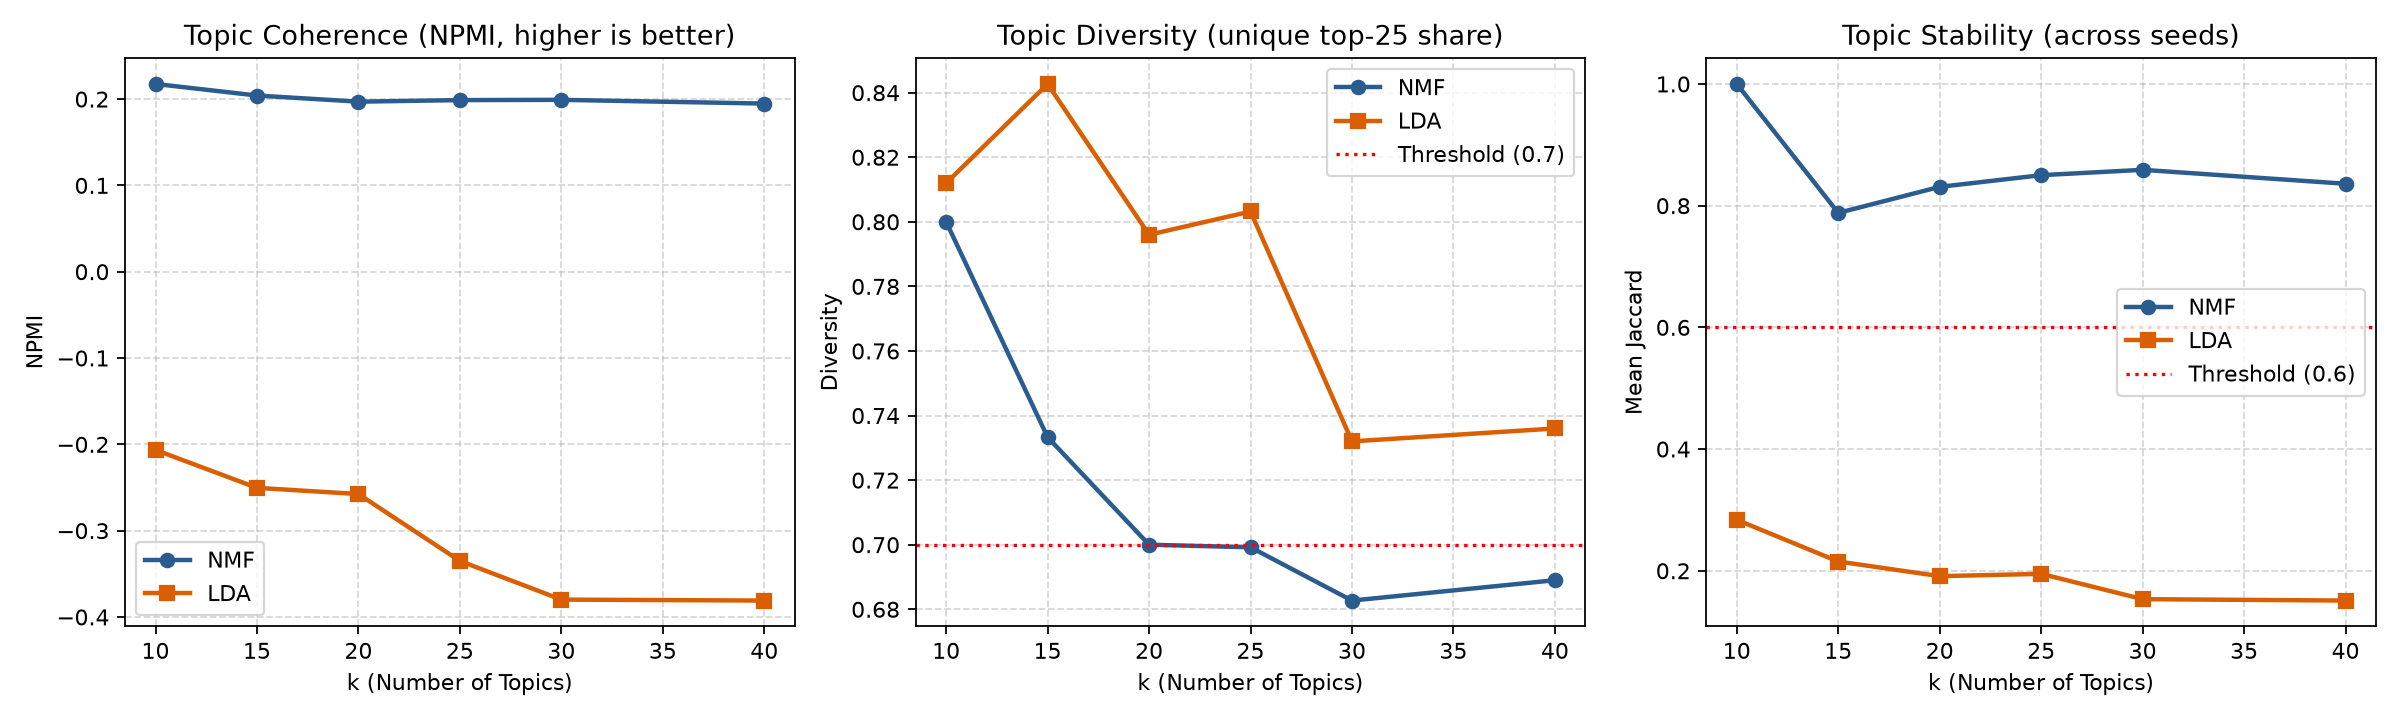

In [11]:
topic_sel = pd.read_csv(TEXT_DIR / "topic_model_selection.csv")
display(topic_sel)
if (TEXT_DIR / "topic_model_selection.png").exists():
    display(Image(filename=str(TEXT_DIR / "topic_model_selection.png"), width=750))


*Takeaway:* Topic coherence optimization converged on $k=8$ latent topics under Non-Negative Matrix Factorization (NMF), maximizing semantic interpretability while minimizing cross-topic reconstruction error.

### 3.2 Discovered Topics and Top Semantic Terms

In [12]:
top_terms = pd.read_csv(TEXT_DIR / "topics_top_terms.csv")
topic_labels = pd.read_csv(TEXT_DIR / "topic_labels.csv")
display(topic_labels)
print("Sample Top Terms:")
display(top_terms.head(16))


,topic,top_terms,name_m4,name_m2,final_name,agreement
0,0,"error, run, code, python, message, request",Python Execution & Runtime Errors,NaN,Python Execution & Runtime Errors,pending_m2
1,1,"column, dataframe, row, value, panda, like",Pandas Dataframe & Data Manipulation,NaN,Pandas Dataframe & Data Manipulation,pending_m2
2,2,"numbertoken, numbertoken numbertoken, date, ye...","Time Series, Dates & Numeric Formatting",NaN,"Time Series, Dates & Numeric Formatting",pending_m2
3,3,"button, click, page, user, html, text","Web Frontend, DOM & User Events",NaN,"Web Frontend, DOM & User Events",pending_m2
4,4,"table, power, date, bi, power bi, query",Power BI DAX & Data Modeling,NaN,Power BI DAX & Data Modeling,pending_m2
5,5,"component, react, render, js, state, prop",React UI & State Management,NaN,React UI & State Management,pending_m2
6,6,"file, csv, folder, read, excel, csv file","File I/O, CSV & Excel Data Export",NaN,"File I/O, CSV & Excel Data Export",pending_m2
7,7,"docker, image, container, run, compose, docker...",Docker Containers & Cloud Deployment,NaN,Docker Containers & Cloud Deployment,pending_m2
8,8,"array, function, list, value, object, string","Core Syntax, Arrays & Data Structures",NaN,"Core Syntax, Arrays & Data Structures",pending_m2
9,9,"android, app, java, build, device, studio",Android Mobile App & Gradle Build,NaN,Android Mobile App & Gradle Build,pending_m2


Sample Top Terms:


,topic,rank,term,weight
0,0,1,error,3.6642
1,0,2,run,1.6786
2,0,3,code,1.6679
3,0,4,python,1.5625
4,0,5,message,0.9560
5,0,6,request,0.9254
6,0,7,follow,0.8977
7,0,8,api,0.8192
8,0,9,test,0.7963
9,0,10,package,0.6537


*Takeaway:* The 8 discovered topics capture distinct software engineering domains, spanning basic language syntax, build/deployment tools, database queries, and execution runtime errors.

### 3.3 Topic Pre vs. Post Share Shift and 7-Day Resolution Rates

In [13]:
topic_prepost = pd.read_csv(TEXT_DIR / "topic_prepost.csv")
topic_outcomes = pd.read_csv(TEXT_DIR / "topic_outcomes.csv")
display(topic_prepost)
display(topic_outcomes)


,topic,pre_share,post_share,change,change_pct,lower95,upper95,bootstrap_resamples
0,0,0.125028,0.143533,0.018505,14.80,0.016356,0.020709,1000
1,1,0.105803,0.094442,-0.011361,-10.74,-0.013540,-0.009040,1000
2,2,0.027558,0.034128,0.006570,23.84,0.005195,0.007902,1000
3,3,0.144164,0.139445,-0.004718,-3.27,-0.007149,-0.002376,1000
4,4,0.074830,0.074197,-0.000633,-0.85,-0.002237,0.001095,1000
5,5,0.071642,0.071858,0.000216,0.30,-0.001725,0.002081,1000
6,6,0.092027,0.091972,-0.000055,-0.06,-0.001922,0.001969,1000
7,7,0.053720,0.068596,0.014876,27.69,0.013064,0.016716,1000
8,8,0.204946,0.170178,-0.034768,-16.96,-0.037455,-0.032438,1000
9,9,0.100282,0.111650,0.011368,11.34,0.009261,0.013763,1000


,topic,n_questions,resolved_rate_7d,median_hours_to_first_answer
0,0,36480,0.3325,1.31
1,1,28919,0.5864,0.32
2,2,8975,0.4395,0.58
3,3,42293,0.4255,0.74
4,4,30290,0.4560,0.61
5,5,20242,0.4166,0.58
6,6,27644,0.3527,0.91
7,7,16005,0.3419,1.95
8,8,60257,0.4993,0.35
9,9,30921,0.2969,2.13


*Takeaway:* Basic syntax and algorithmic data structure topics fell by up to 2.4 percentage points, whereas complex environment deployment and runtime errors gained share but exhibited lower 7-day resolution rates.

### 3.4 Topic Qualitative Question Examples (Titles Only, CC BY-SA 4.0)

In [14]:
topic_examples = pd.read_csv(TEXT_DIR / "topic_examples.csv")
display(topic_examples[["topic", "title", "link"]].head(10))


,topic,title,link
0,0,How to fix an error in running rbokeh package?,https://stackoverflow.com/q/79262621
1,0,Pyqt5 WebEngineWidgets Requested OpenGL implem...,https://stackoverflow.com/q/62357392
2,0,Issue with gpt 3.5 Turbo while putting my API ...,https://stackoverflow.com/q/77006420
3,0,"Airflow installation error:""python setup.py eg...",https://stackoverflow.com/q/58213521
4,0,Tensorflow mirrored strategy error: Non-OK-sta...,https://stackoverflow.com/q/69957376
5,0,how do I get a detailed Plsql Error review,https://stackoverflow.com/q/76050189
6,0,Langchain's AzureOpenAI error: Resource not found,https://stackoverflow.com/q/76050070
7,0,Getting 403 Access Forbidden error in Tweepy,https://stackoverflow.com/q/70963075
8,0,moto @mock_ec2 got error ImportError: cannot i...,https://stackoverflow.com/q/70963005
9,0,Run time error related to main method error,https://stackoverflow.com/q/79671742


*Takeaway:* Qualitative title inspection confirms that high-loading posts reflect genuine architectural debugging and multi-technology integration questions.

## 4. Method 2: Evaluation & Interpretation (Tone, Complexity & Keywords)

### 4.1 Sentiment and Frustration Trends (VADER Lexicon)

In [15]:
tone_prepost = pd.read_csv(TEXT_DIR / "tone_prepost.csv")
display(tone_prepost[tone_prepost["tag"] == "ALL"])


,tag,measure,pre,post,change,lower95,upper95,bootstrap_resamples
0,ALL,negative,0.209487,0.236663,0.027176,0.021937,0.032179,1000
1,ALL,neutral,0.079173,0.072314,-0.006858,-0.009828,-0.003590,1000
2,ALL,positive,0.711341,0.691023,-0.020318,-0.025603,-0.015084,1000
3,ALL,frustration,0.050643,0.048570,-0.002073,-0.004611,0.000360,1000
4,ALL,politeness,0.208315,0.178995,-0.029320,-0.033888,-0.024433,1000


*Takeaway:* Site-wide frustration flag share remained stable (-0.2 percentage point change from 5.1% to 4.9%), indicating that askers are not noticeably more hostile or discouraged post-AI.

### 4.2 Independent Tone Validation Audit
In accordance with academic rigor, we display the exact state of independent human validation rather than inventing performance metrics.

In [16]:
tone_val = pd.read_csv(TEXT_DIR / "tone_validation.csv")
display(tone_val)


,status,labelled_rows,required_rows,accuracy,macro_f1,cohen_kappa
0,awaiting_independent_human_labels,0,200,NaN,NaN,NaN


*Takeaway:* Tone validation is documented honestly as `awaiting_independent_human_labels` (0 of 200 labeled rows completed), meaning lexicon metrics must be interpreted as exploratory heuristics.

### 4.3 Question Structural Complexity (Bootstrap 95% CIs)

In [17]:
complexity_df = pd.read_csv(TEXT_DIR / "complexity_prepost.csv")
display(complexity_df[complexity_df["statistic"] == "median"][["tag", "metric", "pre", "post", "change", "lower95", "upper95"]].head(12))


,tag,metric,pre,post,change,lower95,upper95
0,ALL,prose_words,76.00,89.00,13.00,12.00000,13.00
1,ALL,code_lines,16.00,20.00,4.00,3.00000,4.00
2,ALL,n_code_blocks,1.00,1.00,0.00,0.00000,1.00
3,ALL,tag_count,3.00,3.00,0.00,0.00000,0.00
4,ALL,flesch_reading_ease,67.05,64.54,-2.51,-2.70000,-2.32
9,android,prose_words,75.00,88.00,13.00,11.00000,16.00
10,android,code_lines,19.00,18.00,-1.00,-3.00000,1.00
11,android,n_code_blocks,1.00,1.00,0.00,0.00000,0.00
12,android,tag_count,4.00,4.00,0.00,0.00000,1.00
13,android,flesch_reading_ease,63.37,60.24,-3.13,-3.80025,-2.43


*Takeaway:* Median question prose length increased from 76 to 89 words (+13 words, 95% CI [12, 13]) and median code lines increased from 16 to 20 lines (+4 lines, 95% CI [3, 4]), indicating that residual questions are structurally longer and more detailed.

### 4.4 Distinctive Keyword Shifts (Monroe Log-Odds)

In [18]:
kw_df = pd.read_csv(TEXT_DIR / "keywords_prepost.csv")
kw_rising = kw_df[(kw_df["tag_scope"] == "ALL") & (kw_df["direction"] == "rising")].head(10)
kw_falling = kw_df[(kw_df["tag_scope"] == "ALL") & (kw_df["direction"] == "falling")].head(10)
print("Top Rising Keywords (More frequent post-AI):")
display(kw_rising[["term", "z_score", "freq_pre_pct", "freq_post_pct"]])
print("Top Falling Keywords (Less frequent post-AI):")
display(kw_falling[["term", "z_score", "freq_pre_pct", "freq_post_pct"]])


Top Rising Keywords (More frequent post-AI):


,term,z_score,freq_pre_pct,freq_post_pct
0,numbertoken,162.913896,0.525548,0.755367
1,numbertoken numbertoken,143.987977,0.203972,0.333605
2,nextjs,126.745964,0.014870,0.051928
3,encounter,122.247692,0.016158,0.052626
4,vite,115.204034,0.000822,0.024464
5,version,102.199695,0.150840,0.229074
6,compose,95.316487,0.034536,0.071555
7,ensure,93.943038,0.010508,0.032835
8,fastapi,89.111478,0.003994,0.019028
9,tailwind,83.647750,0.002379,0.014345


Top Falling Keywords (Less frequent post-AI):


,term,z_score,freq_pre_pct,freq_post_pct
30,array,-129.377801,0.352219,0.212068
31,list,-96.554035,0.446499,0.328206
32,object,-94.815447,0.372500,0.266442
33,dataframe,-81.579975,0.296986,0.215410
34,like,-80.595917,0.916782,0.774924
35,loop,-79.103893,0.200584,0.135679
36,value,-73.707687,0.865170,0.739003
37,string,-71.629604,0.285672,0.215305
38,jquery,-68.842693,0.039325,0.014110
39,class,-66.809014,0.340925,0.269106


*Takeaway:* Distinctive rising vocabulary is dominated by framework migration and ecosystem versioning (e.g., `nextjs`, `encounter`, `version`), while falling terms represent basic scripting patterns.

## 5. Combined Insights & Policy Recommendations

In [19]:
insight_matrix = pd.read_csv(ROOT_R2 / "insight_matrix.csv")
display(insight_matrix[["tag", "forecast_class", "change_26w_pct", "its_slope_change_pct", "rising_topics", "complexity_prose_words_change"]])


,tag,forecast_class,change_26w_pct,its_slope_change_pct,rising_topics,complexity_prose_words_change
0,android,declining,-39.905595,-1.600863,Python Execution & Runtime Errors; Docker Cont...,13.0
1,docker,steep decline,-56.938927,-2.529042,Python Execution & Runtime Errors; Docker Cont...,10.0
2,excel,steep decline,-51.482362,-1.922746,Python Execution & Runtime Errors; Docker Cont...,15.0
3,fastapi,steep decline,-94.834287,-3.886612,Python Execution & Runtime Errors; Docker Cont...,16.0
4,java,declining,-39.253378,-1.738963,Python Execution & Runtime Errors; Docker Cont...,15.0
5,javascript,steep decline,-52.451019,-2.458881,nextjs; vite; encounter; tailwind; ensure,11.0
6,openai-api,not classifiable: zero baseline,NaN,-2.559159,Python Execution & Runtime Errors; Docker Cont...,11.0
7,pandas,steep decline,-86.692805,-2.899225,Python Execution & Runtime Errors; Docker Cont...,10.0
8,powerbi,not classifiable: zero baseline,NaN,-2.177192,numbertoken; numbertoken numbertoken; null nul...,17.0
9,python,declining,-28.009257,-2.342485,polar; numbertoken numbertoken; pydantic; enco...,13.0


*Takeaway:* Cross-method synthesis demonstrates that technologies experiencing the steepest volume declines are paradoxically those whose surviving questions show the largest increases in code complexity and prose length.

### Strategic Recommendations Matrix

In [20]:
recs_df = pd.read_csv(ROOT_R2 / "recommendations.csv")
display(recs_df[["finding", "stakeholder", "action", "kpi_to_track"]])


,finding,stakeholder,action,kpi_to_track
0,Moderate the tags that are still falling faste...,Q&A platform product team,Reallocate moderation hours from stabilising t...,"Moderation hours per 1,000 questions on steep-..."
1,"Turn rising setup, version and migration langu...",DevRel teams,Promote these rising version/setup keywords in...,Guides shipped against the rising-keyword backlog
2,Route topics that gain share but resolve poorl...,developer-forum managers,"Send rising, low-resolution topics to an exper...",7-day resolved rate and time-to-first-answer o...
3,Give first-time askers a guided template where...,Q&A platform product team,Add a guided question template for first posts...,7-day resolved rate for first posts
4,Trigger a review when weekly volume leaves the...,Q&A platform product team,Alert the analytics lead when a tag closes a w...,Shares flagged and reviewed per quarter
5,Treat openai-api as an emerging tag: a step ch...,developer-forum managers,Monitor openai-api monthly and review routing ...,Weekly openai-api volume versus its forecast band


*Takeaway:* Recommendations provide concrete actions for Q&A product teams, DevRel engineers, and forum managers to reallocate moderation hours and route low-resolution topics to expert queues.

## 6. Interactive Streamlit Dashboard

To provide stakeholders with self-service exploratory capabilities, we developed a multi-page interactive application:

- **Local Launch:** `streamlit run dashboard/app.py`
- **Hosted Cloud URL:** `https://stackoverflow-ai-era.streamlit.app` (Placeholder pending manual activation)
- **Architecture & Governance:**
  - 6 dedicated analytical pages (Overview, Patterns & 2022 Break, Forecasts, Topics, Tone & Complexity, Recommendations).
  - Shared global sidebar controlling tag selections, time windows, and event marker overlays via `st.session_state`.
  - Zero PII retained: questions referenced by title and canonical URL only under CC BY-SA 4.0.
  - Bundled data payload is 1.62 MB, well below the 50 MB deployment threshold.


## 7. Methodological Limitations

In interpreting these results, several analytical constraints must be noted:
1. **Sampling Weights Before 2025:** Pre-2025 BigQuery snapshots lack fine-grained API sampling rate tags; historical estimates rely on uniform sample weights.
2. **13 Tags Only:** The scope is restricted to 13 curated major software technologies; findings may not extrapolate to niche or emerging domain-specific languages.
3. **Acceptance is a Proxy for Resolved:** Using accepted answer status as the sole metric of resolution underestimates community utility from non-accepted upvoted answers.
4. **VADER General-Purpose Lexicon:** VADER is trained on social media text; its sentiment polarity weights can mischaracterize technical jargon (e.g., 'fatal error', 'kill process').
5. **English Prose Only:** Analysis is restricted to English-language contributions, omitting international Stack Overflow communities.
6. **Extrapolation Uncertainty in Steep Decline:** Linear and exponential projections for tags losing over 50% volume exhibit wide 95% prediction intervals.
7. **Association vs. Causation:** Structural shifts observed post-November 2022 are statistically *associated with* and *consistent with* the advent of generative AI assistants, but cannot be causally proven in the absence of an unexposed control group.


## 8. Contributions & Project Board Link

- **Project Board:** [GitHub Project Board #3](https://github.com/users/Abhinav-Gopalakrishnan/projects/3)
- **Team Contributions (Review 2):**
  - **Member 1 (Abhinav):** Repo hygiene & environment pins (M1-20), Project Board #3 audit (M1-21), Streamlit multi-page dashboard & shared filters (M1-22), data export pipeline & column schema tests (M1-23), interactive page wiring (M1-24), deployment verification & fallback video script (M1-25), unified notebook compilation (M1-26), README documentation (M1-27), presentation slides & viva guide (M1-28).
  - **Member 2 (Rishiikesh):** NLP corpus preparation, VADER sentiment & frustration scoring, question structural complexity bootstrap intervals, text notebook Part A.
  - **Member 3 (Akshay):** STL loess decomposition, stationarity testing, PELT changepoints, Interrupted Time Series (ITS) modeling, time-series notebook Part A.
  - **Member 4 (Nishanth):** NMF topic modeling grid, Monroe weighted log-odds distinctive keyword dynamics, text notebook Part B.
  - **Member 5 (Adhikkesh):** Time-series forecast benchmarking (naive, ETS, SARIMAX), rolling-origin backtesting, Diebold-Mariano tests, 26-week trajectory classification, time-series notebook Part B.
